## EDA on Sales 

- Data Analyze revenue patterns, customer behavior, and seasonality.
- Bar chart of sales by region
- Pie chart of product categories
- Line chart showing monthly revenue trends


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("data_base/superstore_sales.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print(df.head())
print(df.columns.tolist())

Dataset loaded successfully!
Shape: (9994, 9)
   Order Date Region       State         Category Sub-Category    Segment  \
0   11/8/2016  South    Kentucky        Furniture    Bookcases   Consumer   
1   11/8/2016  South    Kentucky        Furniture       Chairs   Consumer   
2   6/12/2016   West  California  Office Supplies       Labels  Corporate   
3  10/11/2015  South     Florida        Furniture       Tables   Consumer   
4  10/11/2015  South     Florida  Office Supplies      Storage   Consumer   

      Sales    Profit  Quantity  
0  261.9600   41.9136         2  
1  731.9400  219.5820         3  
2   14.6200    6.8714         2  
3  957.5775 -383.0310         5  
4   22.3680    2.5164         2  
['Order Date', 'Region', 'State', 'Category', 'Sub-Category', 'Segment', 'Sales', 'Profit', 'Quantity']


In [2]:
print("Missing values before cleaning:")
print(df.isnull().sum())

df = df.drop_duplicates()

for col in ["Order Date", "Order_Date", "order_date"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

print("Shape after cleaning:", df.shape)

Missing values before cleaning:
Order Date      0
Region          0
State           0
Category        0
Sub-Category    0
Segment         0
Sales           0
Profit          0
Quantity        0
dtype: int64
Shape after cleaning: (9992, 9)


In [3]:
print(df.columns.tolist())

['Order Date', 'Region', 'State', 'Category', 'Sub-Category', 'Segment', 'Sales', 'Profit', 'Quantity']


In [5]:
def find_col(options):
    for col in options:
        if col in df.columns:
            return col
    return None

region_col = find_col(["Region", "region"])
category_col = find_col(["Category", "category", "Product Category"])
sales_col = find_col(["Sales", "sales", "Revenue", "revenue"])
date_col = find_col(["Order Date", "Order_Date", "order_date", "Date", "date"])
customer_col = find_col(["Customer Name", "Customer", "customer_name", "Customer ID"])

print("Region:", region_col)
print("Category:", category_col)
print("Sales:", sales_col)
print("Date:", date_col)
print("Customer:", customer_col)

Region: Region
Category: Category
Sales: Sales
Date: Order Date
Customer: None


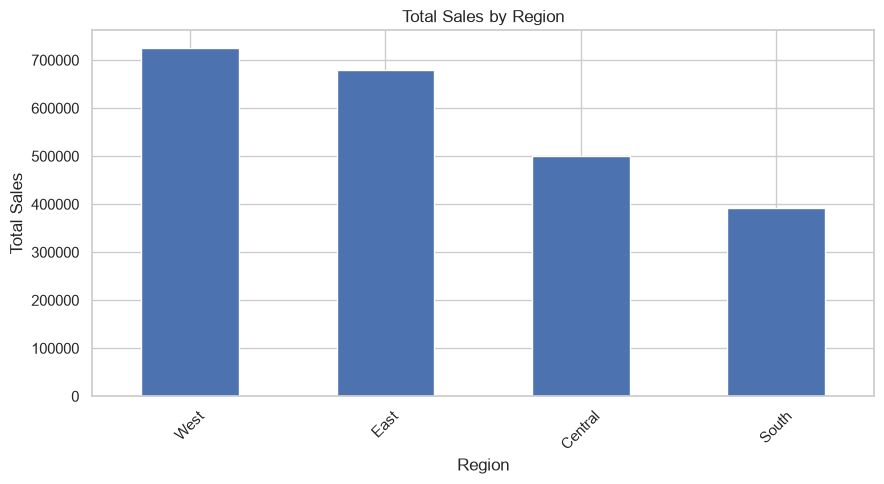

In [6]:
if region_col and sales_col:
    region_sales = df.groupby(region_col)[sales_col].sum().sort_values(
        ascending=False
    )

    region_sales.plot(kind="bar", figsize=(9, 5))
    plt.title("Total Sales by Region")
    plt.xlabel("Region")
    plt.ylabel("Total Sales")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("Region or Sales column not found. Check df.columns.tolist().")

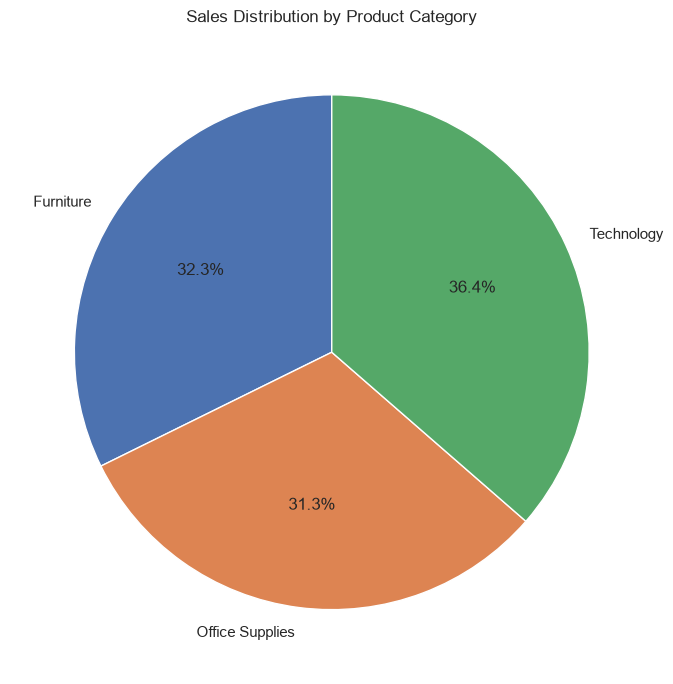

In [7]:
if category_col and sales_col:
    category_sales = df.groupby(category_col)[sales_col].sum()

    plt.figure(figsize=(7, 7))
    plt.pie(
        category_sales,
        labels=category_sales.index,
        autopct="%1.1f%%",
        startangle=90
    )
    plt.title("Sales Distribution by Product Category")
    plt.tight_layout()
    plt.show()
else:
    print("Category or Sales column not found.")

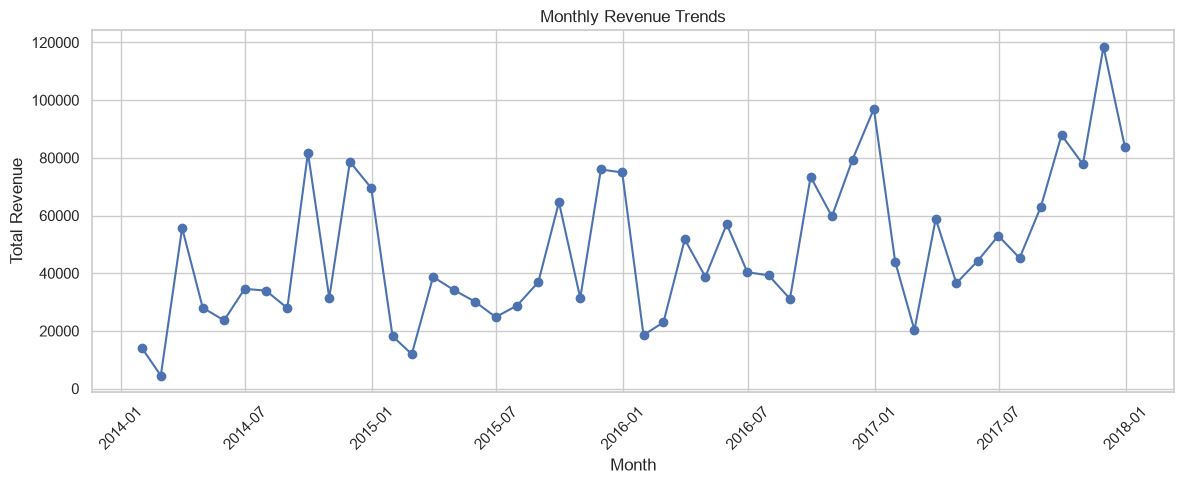

In [8]:
if date_col and sales_col:
    df[date_col] = pd.to_datetime(df[date_col], errors="coerce")

    monthly_sales = (
        df.dropna(subset=[date_col])
          .set_index(date_col)
          .resample("ME")[sales_col]
          .sum()
    )

    plt.figure(figsize=(12, 5))
    plt.plot(monthly_sales.index, monthly_sales.values, marker="o")
    plt.title("Monthly Revenue Trends")
    plt.xlabel("Month")
    plt.ylabel("Total Revenue")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("Date or Sales column not found.")

In [9]:
if customer_col and sales_col:
    top_customers = (
        df.groupby(customer_col)[sales_col]
          .sum()
          .sort_values(ascending=False)
          .head(10)
    )

    print("Top 10 Customers by Sales:")
    print(top_customers)

    top_customers.sort_values().plot(kind="barh", figsize=(9, 5))
    plt.title("Top 10 Customers by Sales")
    plt.xlabel("Total Sales")
    plt.tight_layout()
    plt.show()
else:
    print("No recognized customer column found.")
    

No recognized customer column found.


In [10]:
if sales_col:
    print("Total Sales:", df[sales_col].sum())
    print("Average Sales per Record:", df[sales_col].mean())
    print("Highest Sales Record:", df[sales_col].max())

if date_col and sales_col:
    print("Best Sales Month:")
    print(monthly_sales.idxmax(), monthly_sales.max())

Total Sales: 2296914.5603
Average Sales per Record: 229.87535631505204
Highest Sales Record: 22638.48
Best Sales Month:
2017-11-30 00:00:00 118447.825
